In [1]:
import pymc as pm
import pytensor.tensor as pt
import numpy as np
import matplotlib.pyplot as plt # графики

g++ not available, if using conda: `conda install gxx`


In [2]:
# Объявляем константы

vector3 = np.ndarray

cm = 1
m = 100*cm

golden_ratio_minus_1 = 2/(1+pt.sqrt(5)) # Распределение фотоумножители сделано по спирали Фибоначчи, поэтому нам нужно вот такое число

keV = 1e-3
MeV = 1

In [3]:
def GetPMTCoords(R, N, r): # Получить координаты фотоумножителей

    beta = (pt.pi-pt.arcsin(r/R))/2
    delta_h = r/pt.tan(beta)
    R_photo = R-delta_h

    # Алгоритм по распределению дететкоров по сфере взят из https://arxiv.org/pdf/0912.4540

    N_points = (N-1)/2

    if (N_points % 1 == 0):

        indices = pt.arange(-N_points, N_points+1)
        
    else:

        indices = pt.arange(pt.floor(-N_points), N_points)

    # Изначально задаются сферические углы (тета сдвинут на пи пополам, чтобы покрыть верхнюю и нижнюю полусферы)
    
    theta = pt.arcsin(2*indices/N)+pt.pi/2
    phi = 2*pt.pi*indices*golden_ratio_minus_1

    # Задаётся массив декартовых координат фотокатодов

    photo_coords = R_photo*np.array([pt.sin(theta)*pt.cos(phi), pt.sin(theta)*pt.sin(phi), pt.cos(theta)]).T

    return photo_coords

#### Как определить, попал ли фотон с координатами $(x_0, y_0, z_0) = \vec{r_0}$ и вектором направления $(n_x, n_y, n_z) = \vec{n}$ в ФЭУ?

Известно, что параметризация прямой при заданных $\vec{r_0}, \vec{n}$ выглядит как $\vec{r} = \vec{r_0}+\vec{n}t$
Необходимо найти t при котором $r^2=R$:

$x^2+y^2+z^2-R^2 = (x_0+n_xt)^2+(y_0+n_yt)^2+(z_0+z_xt)^2-R^2 = (n_x^2+n_y^2+n_z^2)t^2+2(x_0n_x+y_0n_y+z_0n_z)t-R^2+y_0^2+x_0^2+z_0^2=t^2+2(\vec{r_0}, \vec{n})t-R^2+r_0^2=0$

Решая квадратное уравнение, получаем:
$t=-(\vec{r_0}, \vec{n})+\sqrt{(\vec{r_0}, \vec{n})^2+R^2-r_0^2}$

Подставив, полученное t в параметризацию, найдём координаты пересечения траектории фотона со сферой. Далее можно применить функцию, определяющую принадлежит ли точка на поверхности ФЭУ

In [4]:
def GeneratePhotonEndPoint(source_coords : vector3, direction : vector3, R : float): # Получаем точку на сфере, в которую прилетит фотон

    x_dir, y_dir, z_dir = direction
        
    source_coord_norm2 = pt.linalg.norm(source_coords)**2
    scalar_product = source_coords[0]*x_dir + source_coords[1]*y_dir + source_coords[2]*z_dir
    Discr = scalar_product**2+R**2-source_coord_norm2
    root = -scalar_product+pt.sqrt(Discr)

    EndPointX = source_coords[0] + x_dir*root
    EndPointY = source_coords[1] + y_dir*root
    EndPointZ = source_coords[2] + z_dir*root

    return [EndPointX, EndPointY, EndPointZ]

In [5]:
def IsCloseToPMT(EndPoint : vector3, photo_coords : vector3, r : float):  # Проверка, попал ли фотон на ФЭУ

    RelX = photo_coords[0]-EndPoint[0]
    RelY = photo_coords[1]-EndPoint[1]
    RelZ = photo_coords[2]-EndPoint[2]
    
    DistancesSq = RelX**2+RelY**2+RelZ**2
    ClosestDistanceInd = pt.argmin(DistancesSq)

    filt = (DistancesSq[ClosestDistanceInd] <= r**2)

    return [filt, ClosestDistanceInd] # Получаем булевый индикатор попадания на ФЭУ и номер ближайшего фотоумножителя

In [6]:
def GetPhotonDirectionModel(): # PyMC-модель для генерации направлений разлёта фотонов

    with pm.Model() as photon_direction_model:
    
        # Изотропно -> равномерно по косинусу тета и равномерно по фи
        cos_theta = pm.Uniform('cos_theta', -1, 1)
        sin_theta = pm.Deterministic('sin_theta', pt.sqrt(1-cos_theta**2))
        phi = pm.Uniform('phi', 0, 2*pt.pi)
    
        # Получаем координаты фотона
        photon_x_dir = pm.Deterministic('photon_x_dir', sin_theta*pt.cos(phi))
        photon_y_dir = pm.Deterministic('photon_y_dir', sin_theta*pt.sin(phi))
        photon_z_dir = pm.Deterministic('photon_z_dir', cos_theta)

    return photon_direction_model

In [7]:
def GenerateFullResponseModel(DetectorInfo: vector3, SourceCoords: vector3): # Полная модель для генерации сигнала на выходе фотокатода

    R, N, r, a = DetectorInfo # Параметры детектора

    photo_coords = GetPMTCoords(R, N, r) # Координаты ФЭУ

    photon_direction_model = GetPhotonDirectionModel() # Модель для генерации направлений

    with pm.Model() as FullResponseModel:

        photon_x_dir = photon_direction_model['photon_x_dir']
        photon_y_dir = photon_direction_model['photon_y_dir']
        photon_z_dir = photon_direction_model['photon_z_dir']

        direction = [photon_x_dir, photon_y_dir, photon_z_dir]

        EndPoint = GeneratePhotonEndPoint(SourceCoords, direction, R) # Получаем точку, в которую прийдёт фотон с заданным направлением
        
        Multiplier, ClosestInd = IsCloseToPMT(EndPoint, photo_coords, r)  # Близок ли фотон к ФЭУ (0 или 1), и номер этого ФЭУ
        
        PhotoectronOnHit = pm.Poisson('PhotoectronOnHit', a) # Сколько фотоэлектронов даст фотон?
        #N_photoelectrons = pm.Deterministic('N_photoelectrons', Multiplier*PhotoectronOnHit)
        HitIdentificator = pm.Deterministic('HitIdentificator', Multiplier) # Попал ли он на ФЭУ
        ClosestPMT = pm.Deterministic('ClosestPMT', ClosestInd)

    return FullResponseModel

In [8]:
# Задаём параметры детектора и координаты источника

R = 2*m
N = 40
r=10*cm
a=0.5

x_pos = -1.1*m
y_pos = 0.7*m
z_pos = -0.2*m

DetectorInfo = np.array([R, N, r, a])
SourceCoords = np.array([x_pos, y_pos, z_pos])

MyModel = GenerateFullResponseModel(DetectorInfo, SourceCoords)

In [9]:
E = 6*MeV
SourceY = 20000/MeV

SizeOfOneChunk = int(E*SourceY)

In [10]:
# 1 сэмпл

N_Chunks = 1

with MyModel:
    
    trace = pm.sample(SizeOfOneChunk*N_Chunks, chains=1)

Sequential sampling (1 chains in 1 job)
Metropolis: [PhotoectronOnHit]


Output()

Sampling 1 chain for 1_000 tune and 120_000 draw iterations (1_000 + 120_000 draws total) took 14 seconds.
Only one chain was sampled, this makes it impossible to run some convergence checks


In [11]:
PhotoElectrons = trace.posterior['PhotoectronOnHit'].values.flatten()
HitFilt = trace.posterior['HitIdentificator'].values.flatten()
PMTinds = trace.posterior['ClosestPMT'].values.flatten()

In [12]:
GoodElectrons = PhotoElectrons[HitFilt]
GoodInds = PMTinds[HitFilt]

DetectorElectrons = np.zeros(N)

for i in range(N):

    filt = (GoodInds==i)
    DetectorElectrons[i] = GoodElectrons[filt].sum()

In [13]:
DetectorElectrons

array([ 15.,  26.,  23.,  28.,  27.,  19.,  52.,  19.,  14.,  16.,  13.,
        78.,  13.,  18.,  43.,  17.,  54.,  29.,  17., 230.,  13.,  25.,
        37.,  16., 135.,  21.,  11.,  85.,  21.,  52.,  24.,  10., 106.,
        17.,  25.,  46.,  24.,  39.,  30.,  20.])

### Правдоподобие

Общее количество образовавшихся фотонов есть $NY$. Вероятность попасть на конкретный фотокатод определяется телесным углом $\Omega$, который он занимает (Ещё нужно не забыть поделить на $4 \pi$). Каждый фотон даёт в среднем $a$ фотоэлектронов. Вспомнив, что по определнию телесного угла $\Omega=\frac{\pi r^2}{d^2}$, где $r$ - радиус фотокатода, а $d$ - расстояние от источника до этого фотокатода, получим итоговую формулу:

$n_i = EY\cdot\frac{\Omega_i}{4\pi}\cdot a = EY\cdot\frac{r^2}{4d_i^2}\cdot a$

In [14]:
with pm.Model() as ReconstructionModel:
    # Приоры
    E = pm.Uniform('E', 0, 10*MeV) # Энергия неотрицательна
    # Координата по каждой из осей равномерна
    position_x = pm.Uniform('position_x', -2*m, 2*m)
    position_y = pm.Uniform('position_y', -2*m, 2*m)
    position_z = pm.Uniform('position_z', -2*m, 2*m)

    photo_coords = GetPMTCoords(R, N, r)
    d_sq = (photo_coords[0]-position_x)**2+(photo_coords[1]-position_y)**2+(photo_coords[2]-position_z)**2
    Lambdas = pm.Deterministic('Lambdas', E*SourceY*r**2/(4*d_sq)*a)
    
    # Правдоподобие
    y = pm.Poisson('y', mu=Lambdas, observed=DetectorElectrons)

In [15]:
# Приоры и постериоры

with ReconstructionModel:
    prior = pm.sample_prior_predictive(10000).prior
    posterior = pm.sample(10000).posterior

Sampling: [E, position_x, position_y, position_z, y]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [E, position_x, position_y, position_z]


Output()

Sampling 4 chains for 1_000 tune and 10_000 draw iterations (4_000 + 40_000 draws total) took 12 seconds.


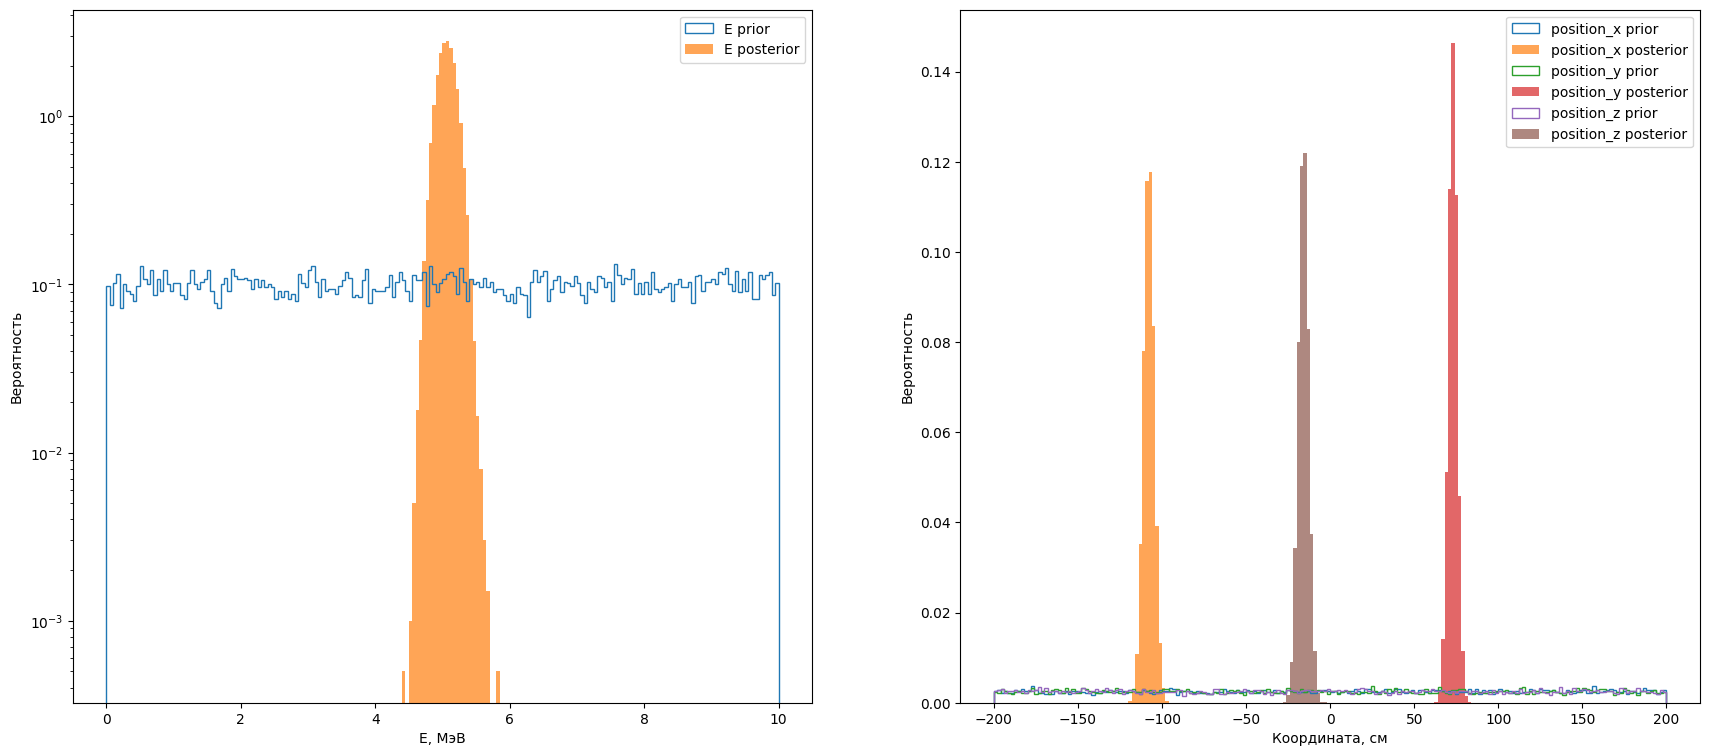

In [16]:
# Рисуем априорные и апостериорные распределения для E (слева) и для координат (справа)

fig, axs = plt.subplots(1,2, figsize=(21, 9))

LocationBins = np.linspace(-2*m,2*m, 201)
EnergyBins = np.linspace(0, 10, 201)

for name in ['E']:
    samples_pri = prior[name].values.flatten()
    samples_pos = posterior[name].values.flatten()
    axs[0].hist(samples_pri, bins=EnergyBins, histtype='step', density=True, label=f'{name} prior')
    axs[0].hist(samples_pos, bins=EnergyBins, alpha=0.7, density=True, label=f'{name} posterior')

    axs[0].set_xlabel('E, МэВ')
    axs[0].set_ylabel('Вероятность')
    
    axs[0].legend(loc='upper right')
    axs[0].set_yscale('log')

for name in ['position_x', 'position_y', 'position_z']:

    samples_pri = prior[name].values.flatten()
    samples_pos = posterior[name].values.flatten()
    axs[1].hist(samples_pri, bins=LocationBins, histtype='step', density=True, label=f'{name} prior')
    axs[1].hist(samples_pos, bins=LocationBins, alpha=0.7, density=True, label=f'{name} posterior')
    axs[1].legend(loc='upper right')

    axs[1].set_xlabel('Координата, см')
    axs[1].set_ylabel('Вероятность')